In [1]:
!pip install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

In [2]:
raisin = fetch_ucirepo(id=850)

X_df = raisin.data.features
y_df = raisin.data.targets

print("Features shape:", X_df.shape)
print("Features:", list(X_df.columns))
print("\nClass distribution:\n", y_df.iloc[:, 0].value_counts())
X_df.head()

Features shape: (900, 7)
Features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']

Class distribution:
 Class
Kecimen    450
Besni      450
Name: count, dtype: int64


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251


Preprocessing

In [3]:
print("Missing values:", X_df.isnull().sum().sum())
print(X_df.describe().T[['mean', 'std', 'min', 'max']])

# Encode labels: Besni = 1, Kecimen = 0
y = y_df.iloc[:, 0].map({'Besni': 1, 'Kecimen': 0}).values.astype(int)
X = X_df.values.astype(float)

# Shuffle and split 80/20 manually
np.random.seed(42)
idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Standardize using TRAIN statistics only (avoids data leakage)
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("\nTrain:", X_train.shape, "Test:", X_test.shape)

Missing values: 0
                         mean           std           min            max
Area             87804.127778  39002.111390  25387.000000  235047.000000
MajorAxisLength    430.929950    116.035121    225.629541     997.291941
MinorAxisLength    254.488133     49.988902    143.710872     492.275279
Eccentricity         0.781542      0.090318      0.348730       0.962124
ConvexArea       91186.090000  40769.290132  26139.000000  278217.000000
Extent               0.699508      0.053468      0.379856       0.835455
Perimeter         1165.906636    273.764315    619.074000    2697.753000

Train: (720, 7) Test: (180, 7)


Perceptron from scratch

In [4]:
class Perceptron:
    def __init__(self, lr=0.01, epochs=100):
        self.lr = lr
        self.epochs = epochs

    def activation(self, z):
        return np.where(z >= 0, 1, 0)   # step function

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.errors = []
        for epoch in range(self.epochs):
            err = 0
            for xi, target in zip(X, y):
                pred = self.activation(np.dot(xi, self.w) + self.b)
                update = self.lr * (target - pred)
                self.w += update * xi
                self.b += update
                err += int(update != 0)
            self.errors.append(err)
        return self

    def predict(self, X):
        return self.activation(np.dot(X, self.w) + self.b)

Train and plot training error

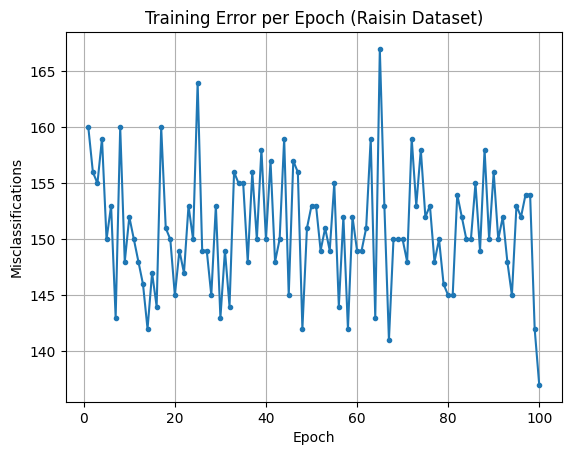

Learned weights:
  Area                  -0.0492
  MajorAxisLength       -0.0132
  MinorAxisLength       -0.0021
  Eccentricity           0.0053
  ConvexArea             0.0611
  Extent                -0.0028
  Perimeter              0.0461
Bias: 0.01


In [5]:
model = Perceptron(lr=0.01, epochs=100)
model.fit(X_train, y_train)

plt.plot(range(1, len(model.errors) + 1), model.errors, marker='o', markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Training Error per Epoch (Raisin Dataset)")
plt.grid(True)
plt.show()

print("Learned weights:")
for name, w in zip(X_df.columns, model.w):
    print(f"  {name:20s} {w:8.4f}")
print("Bias:", round(model.b, 4))

Evaluation metrics

In [6]:
y_pred = model.predict(X_test)

TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

accuracy  = (TP + TN) / len(y_test)
precision = TP / (TP + FP) if (TP + FP) else 0
recall    = TP / (TP + FN) if (TP + FN) else 0
f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

print("Confusion Matrix:")
print("               Pred Kecimen  Pred Besni")
print(f"Actual Kecimen    {TN:5d}        {FP:5d}")
print(f"Actual Besni      {FN:5d}        {TP:5d}\n")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Confusion Matrix:
               Pred Kecimen  Pred Besni
Actual Kecimen       75           10
Actual Besni         12           83

Accuracy : 0.8778
Precision: 0.8925
Recall   : 0.8737
F1-Score : 0.8830


Confusion matrix plot

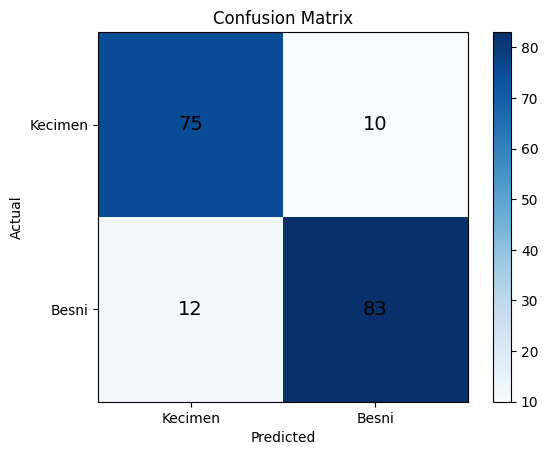

In [7]:
cm = np.array([[TN, FP], [FN, TP]])
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xticks([0, 1], ["Kecimen", "Besni"])
plt.yticks([0, 1], ["Kecimen", "Besni"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)
plt.colorbar()
plt.show()